# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2025-11-27"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater) 
library(Matrix)
}))

## Parameters

In [3]:
patient <- "p1"
subproj <- "AVGUSTINOVA_10_11"

assay_ch <- "RNA_decontx"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [6]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "AFF3"     "RBMS3"    "ROBO2"    "ROBO1"    "LSAMP"    "CACNA2D1"
 [7] "CNTNAP2"  "PRKG1"    "MALAT1"   "NPAS3"    "RAD51B"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)
reso

[1] 0.1

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))

In [10]:
DefaultAssay(seurat_obj) <- assay_ch

## Re-normalize and cluster

In [11]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <-  as(seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ],"sparseMatrix")
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [12]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [13]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

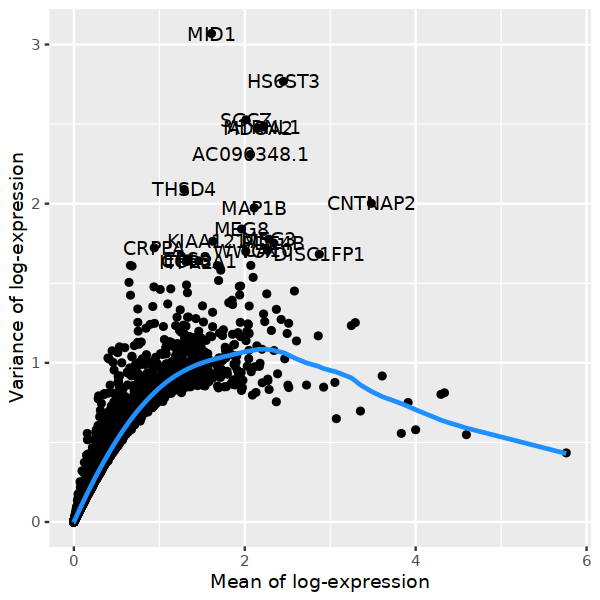

In [14]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [15]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 2443
[1] 2442


In [16]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  ADGRG6, CFAP299, SEMA3E, DLGAP1, AHR, MIR99AHG, PLOD2, TRPA1, PDE3A, FGF5 
	   SASH1, BMP6, SNAP25, COL6A3, CD34, FRK, PCAT1, AGR2, MACROD2, CPNE8 
	   CAP2, SLC35F1, MSC-AS1, LTBP2, SCN9A, PCSK5, PGK1, CHRM2, MLIP, JAG1 
Negative:  EPS8, GLIS3, BRINP3, CA10, TSHZ2, KIAA1217, IQCH, DISC1FP1, CRPPA, CENPP 
	   DLG2, SGIP1, WWOX, PDE4B, SLC8A1, ENOX2, KCTD16, GRIN2A, ADGRL3, SAMD3 
	   MEG8, LUZP2, GALNT13, DIAPH2, KCNJ3, AC090348.1, CALCR, OLFM3, RYR3, DIAPH3 
PC_ 2 
Positive:  MID1, ANGPT1, CACNA1D, MAP1B, OXR1, RASGEF1B, RASAL2, HS6ST3, GLCCI1, EML6 
	   MTTP, CECR2, LINC01151, RNLS, CD69, KIF13B, CLEC2A, AC012499.1, PFKFB4, PGK1 
	   LINC02470, WSB1, KRT23, KDM7A, RALGPS2, SLC2A3, BNIP3L, FAM160A1, CXCR4, ERO1A 
Negative:  DLGAP1, CFAP299, ADGRG6, SEMA3E, SAMD3, AHR, TRPA1, MIR99AHG, PLOD2, PDE3A 
	   ANK3, GLIS3, EPS8, POSTN, SNAP25, SASH1, FGF5, PCAT1, BMP6, COL6A3 
	   PDE4B, CPNE8, CD34, FRK, MSC-AS1, MACROD2, SEMA5A, AGR2, SLC

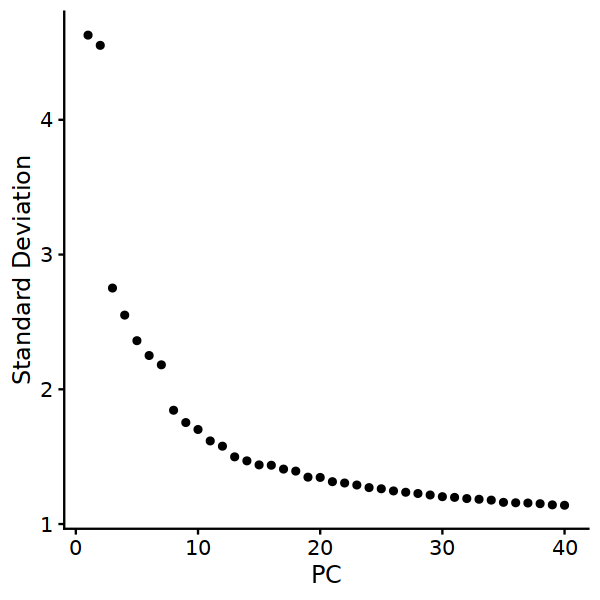

In [17]:
ElbowPlot(seurat_obj, n=40)

In [18]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


15:15:43 UMAP embedding parameters a = 0.9922 b = 1.112

15:15:43 Read 5965 rows and found 20 numeric columns

15:15:43 Using Annoy for neighbor search, n_neighbors = 30

15:15:43 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:15:44 Writing NN index file to temp file /scratch_tmp/49729482/Rtmpwh9f5p/file20eda6d82ccbc

15:15:44 Searching Annoy index using 1 thread, search_k = 3000

15:15:45 Annoy recall = 100%

15:15:46 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:15:46 17 smooth knn distance failures

15:15:48 Initializing from normalized Laplacian + noise (using irlba)

15:15:48 Commencing optimization for 500 epochs, with 246542 positive edges

15:16:05 Optimization f

In [19]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [20]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

15:16:22 UMAP embedding parameters a = 0.9922 b = 1.112

15:16:23 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

15:16:24 Initializing from normalized Laplacian + noise (using irlba)

15:16:24 Commencing optimization for 500 epochs, with 176968 positive edges

15:16:43 Optimization finished



In [21]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = as.numeric(reso),
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5965
Number of edges: 218676

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9769
Number of communities: 10
Elapsed time: 0 seconds


1 singletons identified. 9 final clusters.



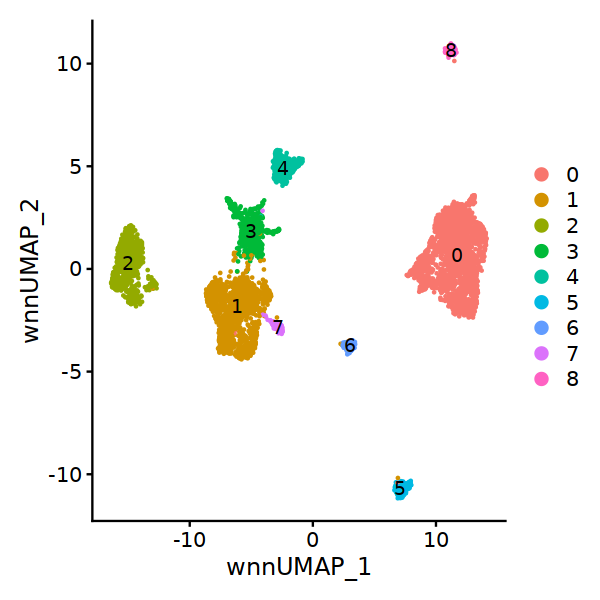

In [22]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

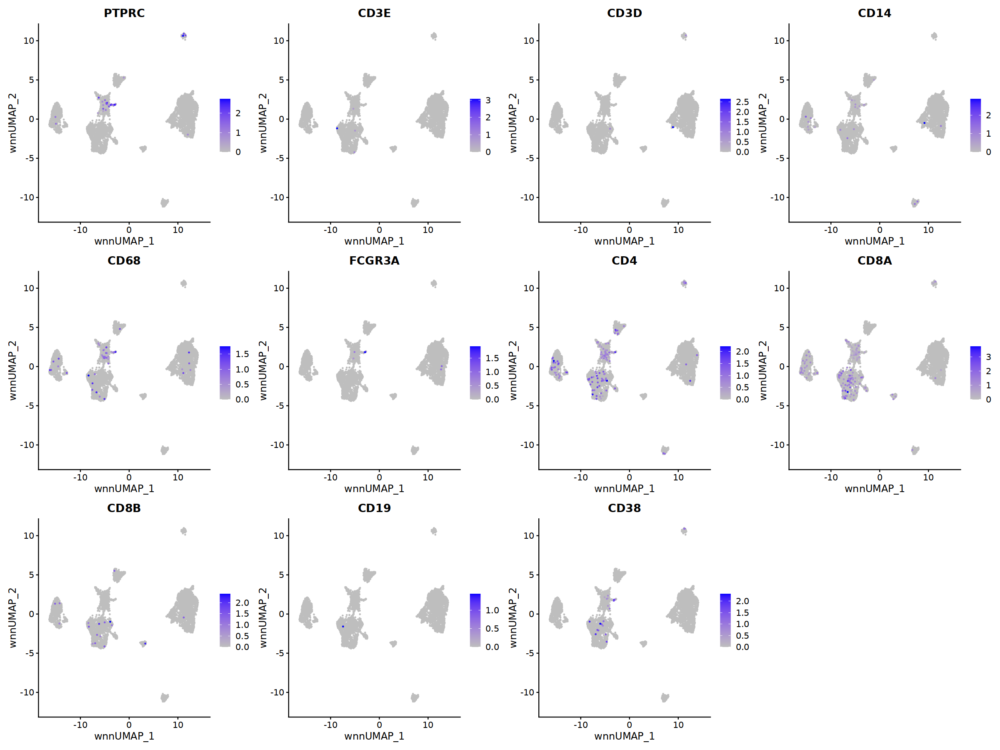

In [23]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

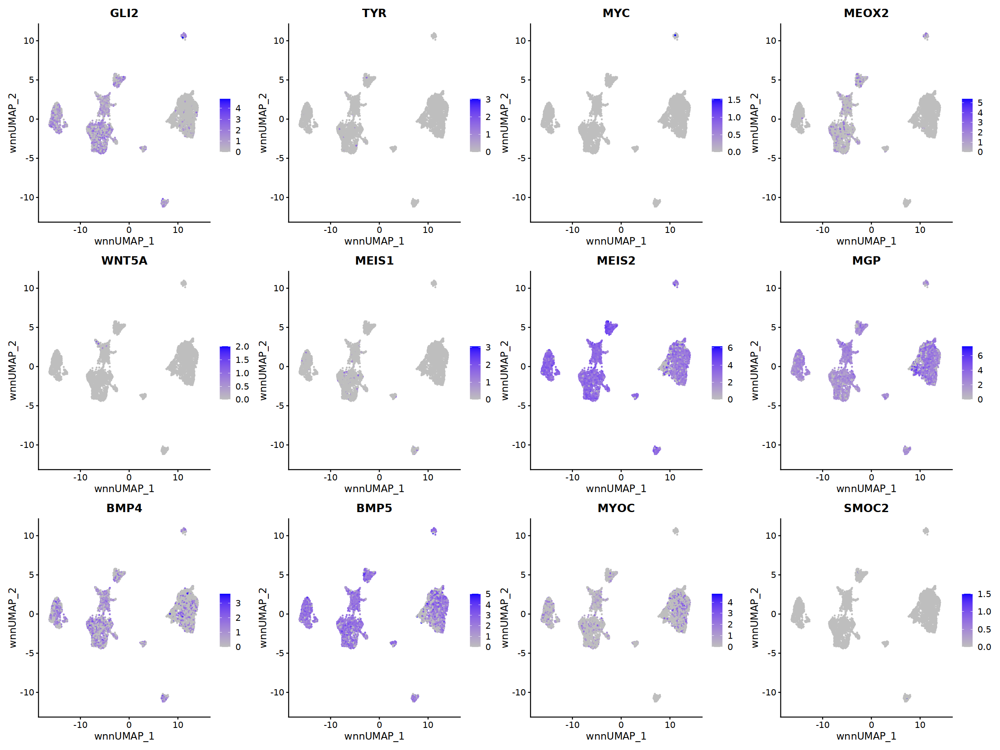

In [24]:
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

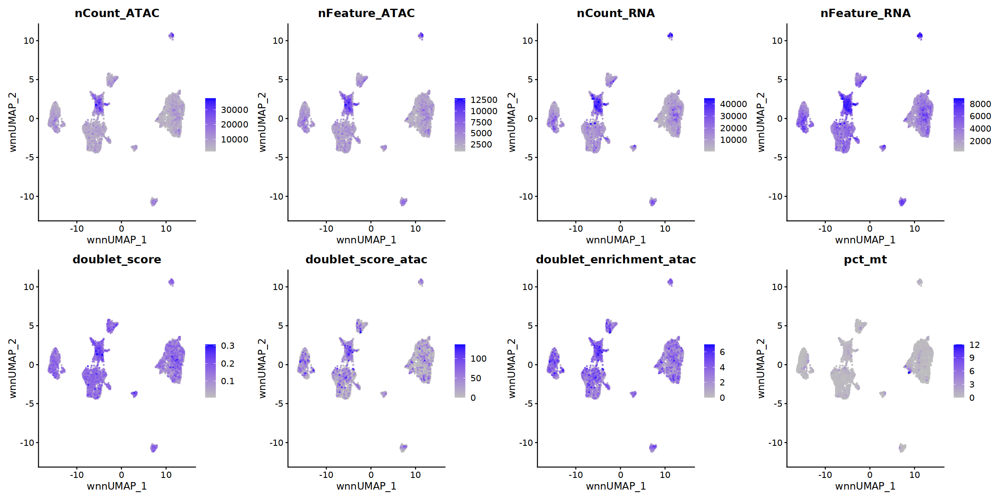

In [25]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

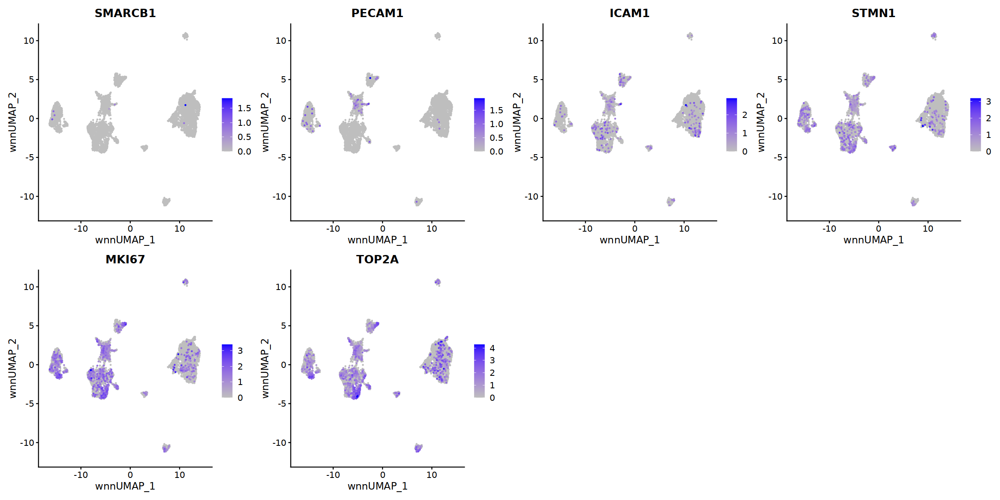

In [26]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1",
           "MKI67","TOP2A")

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

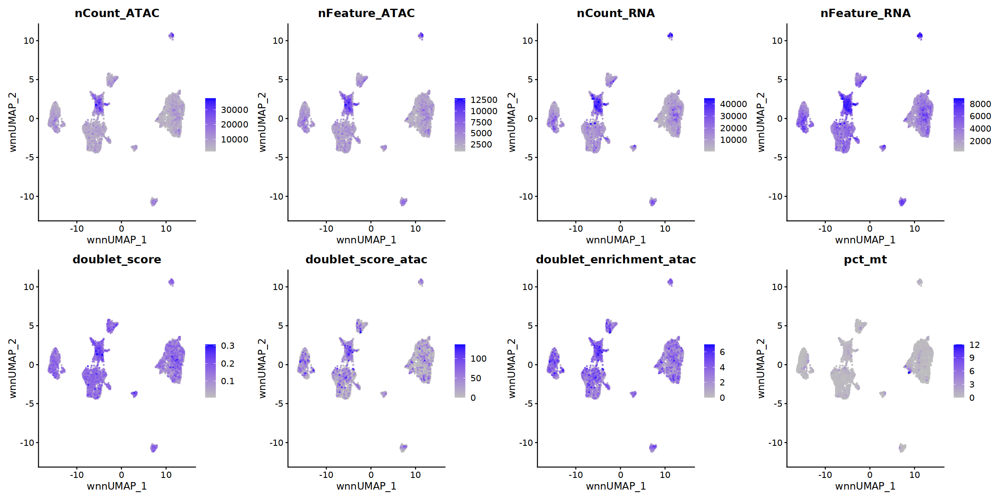

In [27]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

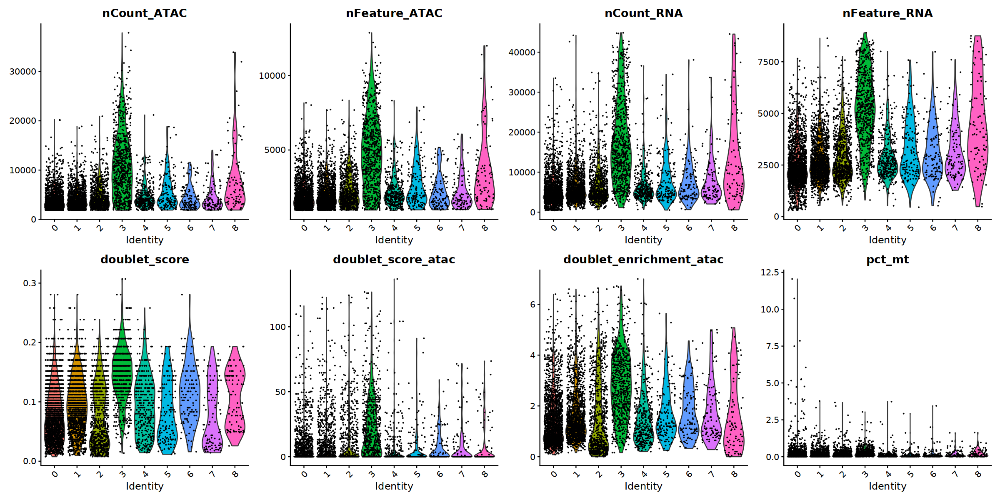

In [28]:
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4)

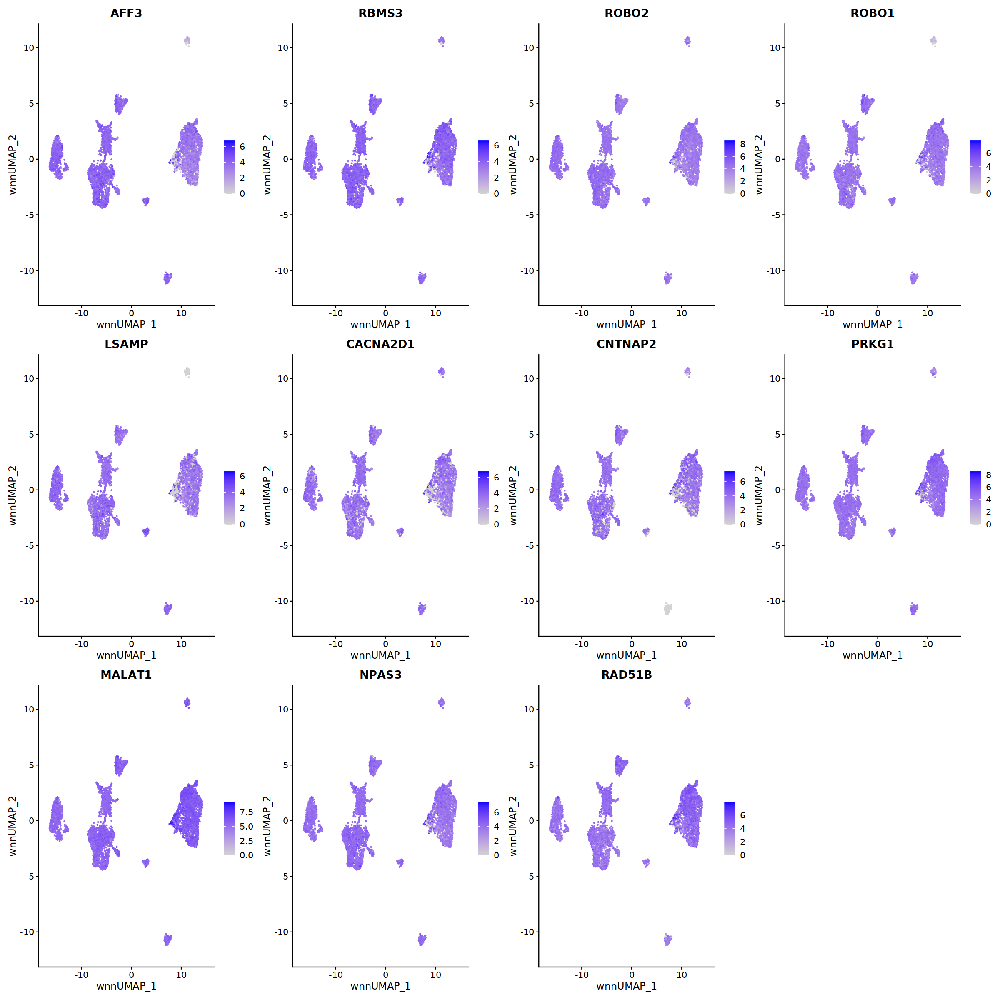

In [29]:
options(repr.plot.width = 20, repr.plot.height = 20)
FeaturePlot(seurat_obj, features = top_counts, reduction = "wnn.umap",
            order=F)

In [30]:
seurat_obj <- FindSubCluster(
  seurat_obj,
  3,
  graph.name = "wsnn",
  subcluster.name = "subclustering",
  resolution = 0.3,
  algorithm = 1
)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 697
Number of edges: 26310

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8229
Number of communities: 3
Elapsed time: 0 seconds


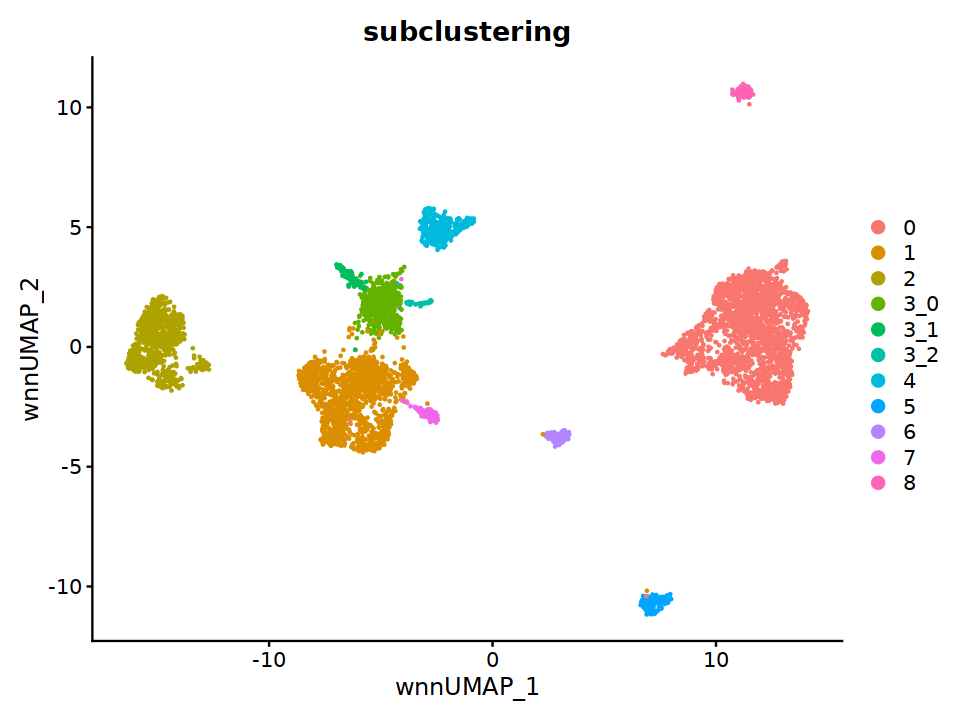

In [31]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", group.by = "subclustering", label = F, label.size = 6)

In [32]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data[["subclustering"]])

In [33]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 3_1

Calculating cluster 1

Calculating cluster 3_0

Calculating cluster 0

Calculating cluster 8

Calculating cluster 4

Calculating cluster 2

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 3_2



In [34]:
rna.markers %>% 
  dplyr::filter(cluster == "3_3") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>


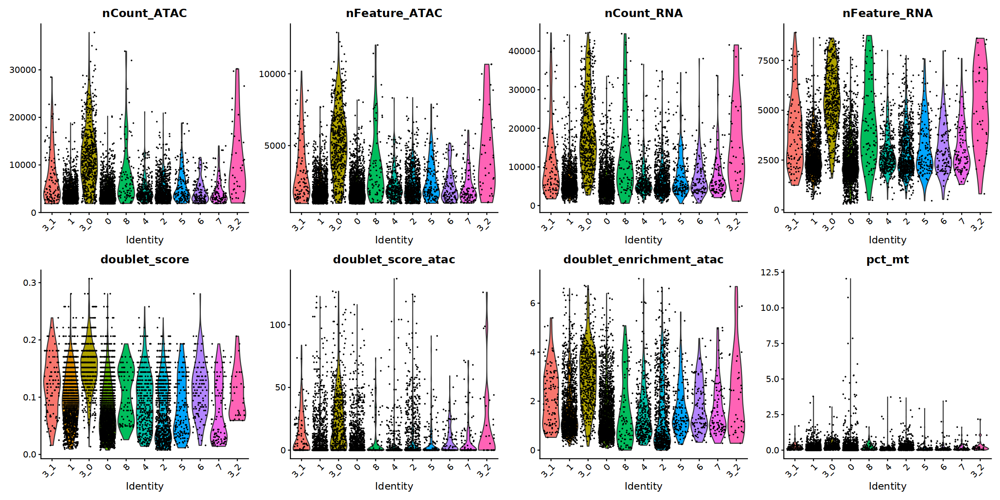

In [35]:
options(repr.plot.width = 20, repr.plot.height = 10)
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4)

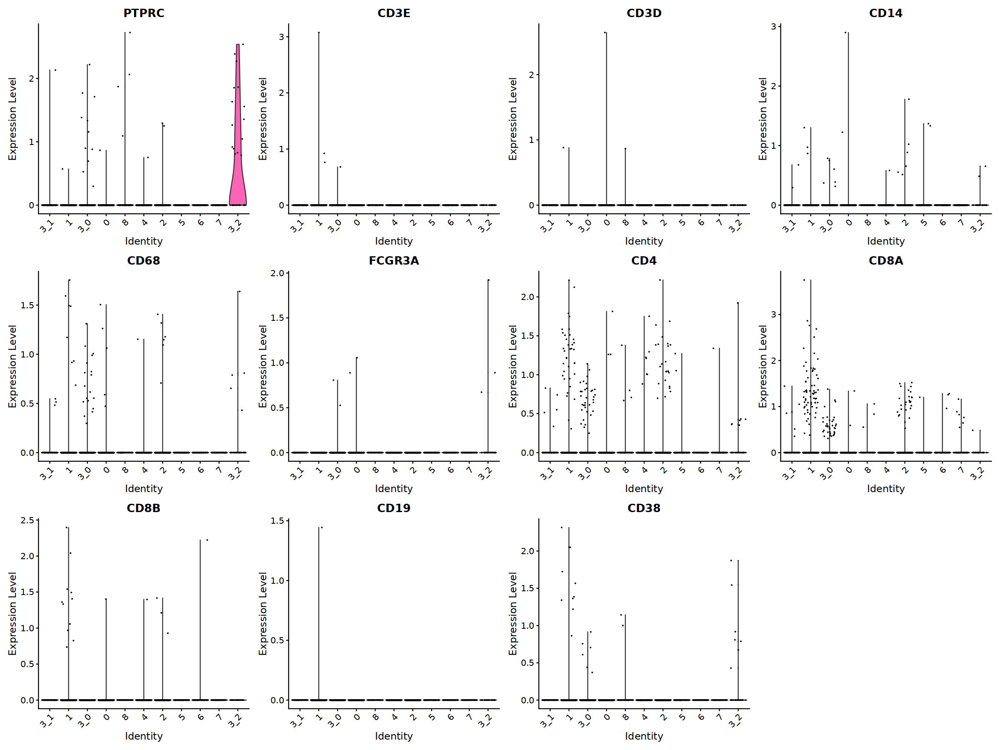

In [36]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

VlnPlot(seurat_obj, feature=vars2plot, ncol = 4)

## Filter cells

Cluster 3 contains doublets

In [37]:
seurat_obj <- subset(seurat_obj, idents = c("3_0", "3_1", "3_2"), invert = TRUE)

In [38]:
DefaultAssay(seurat_obj) <- assay_ch

In [39]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [40]:
keep_peaks <- data.frame(rowSums(as.matrix(seurat_obj[['ATAC']]@counts)) >= 1)
colnames(keep_peaks) <- "logical"
keep_peaks <- subset(keep_peaks, logical==TRUE)
seurat_obj[['ATAC']]@counts <- seurat_obj[['ATAC']]@counts[rownames(keep_peaks), ]
seurat_obj[['ATAC']]@data <- seurat_obj[['ATAC']]@data[rownames(keep_peaks), ]

### RNA

In [41]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [42]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

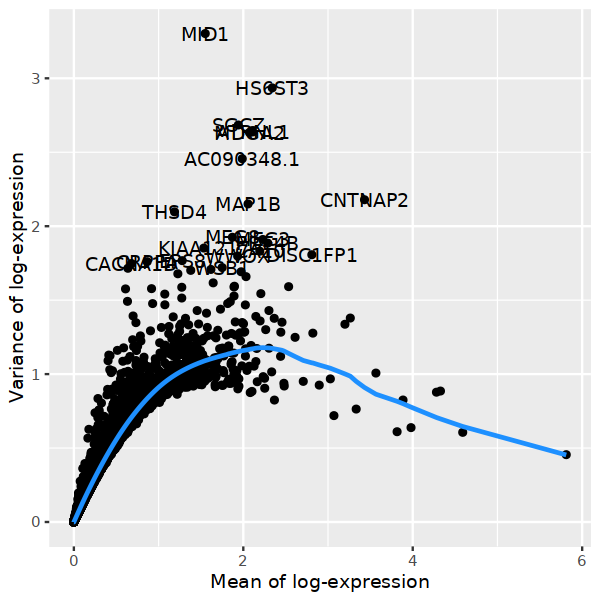

In [43]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [44]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  SAMD3, CFAP299, DLGAP1, GLIS3, ADGRG6, EPS8, SEMA3E, ANK3, AHR, TRPA1 
	   MIR99AHG, PDE4B, PDE3A, PLOD2, POSTN, SNAP25, SASH1, FGF5, PCAT1, SEMA5A 
	   BMP6, COL6A3, FRK, TSHZ2, CPNE8, CD34, IQCH, MACROD2, LDB2, AGR2 
Negative:  MID1, ANGPT1, CACNA1D, MAP1B, OXR1, RASGEF1B, RASAL2, HS6ST3, GLCCI1, EML6 
	   MTTP, RNLS, LINC01151, CECR2, CD69, KIF13B, CLEC2A, AC012499.1, LINC02470, KRT23 
	   RALGPS2, WSB1, LINC02197, PFKFB4, PGK1, PAPSS2, ITGA8, AC037486.1, LINC01198, LINC02306 
PC_ 2 
Positive:  ADGRG6, CFAP299, SEMA3E, DLGAP1, AHR, MIR99AHG, TRPA1, PLOD2, PDE3A, FGF5 
	   SASH1, BMP6, SNAP25, COL6A3, CD34, FRK, PCAT1, AGR2, MACROD2, CPNE8 
	   SLC35F1, LTBP2, PCSK5, SCN9A, CHRM2, MLIP, JAG1, GPM6A, CGNL1, DNAJC15 
Negative:  EPS8, GLIS3, KIAA1217, TSHZ2, CA10, IQCH, DISC1FP1, SGIP1, CRPPA, DLG2 
	   CENPP, SLC8A1, WWOX, ENOX2, PDE4B, KCTD16, GRIN2A, ADGRL3, LUZP2, CALCR 
	   SAMD3, DIAPH2, OLFM3, GALNT13, MEG8, KCNJ3, AC109466.1, 

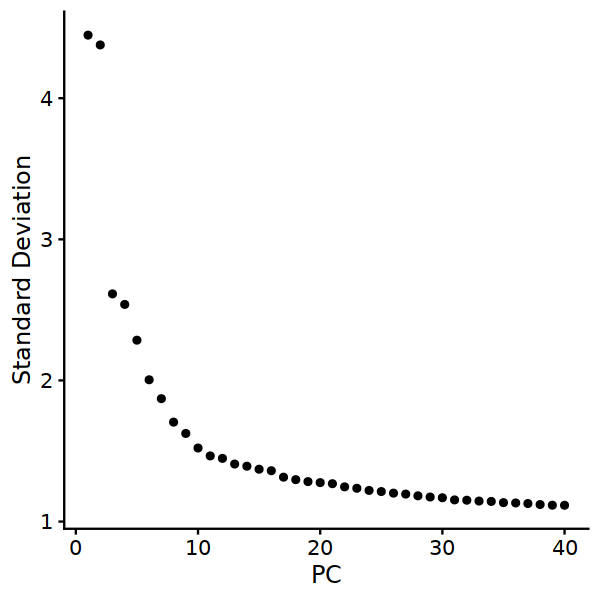

In [45]:
ElbowPlot(seurat_obj, n=40)

### ATAC

In [46]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [47]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



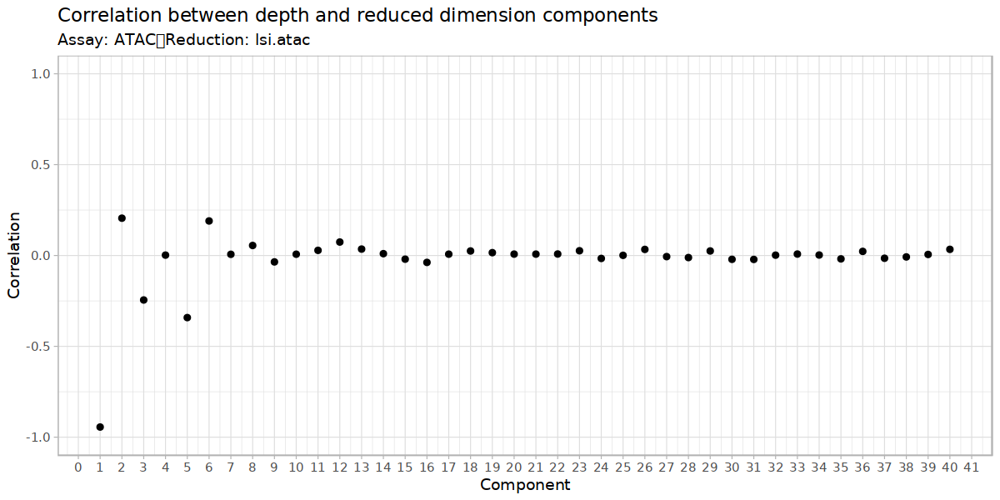

In [48]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

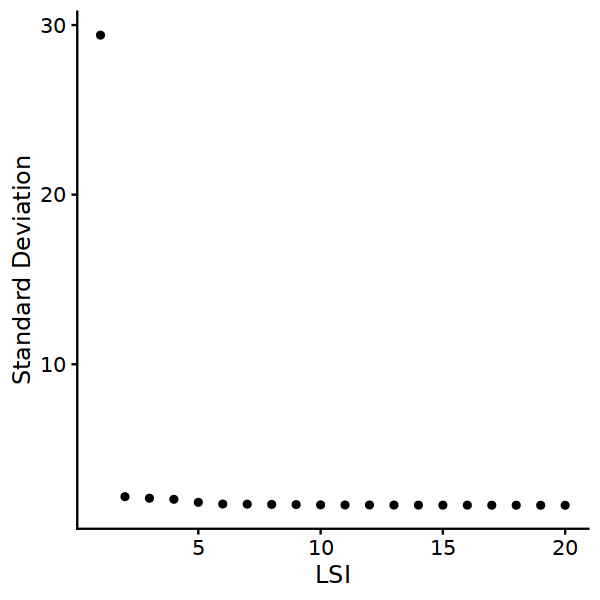

In [49]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [50]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [51]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells 
)

15:21:35 UMAP embedding parameters a = 0.115 b = 1.929

15:21:36 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

15:21:38 Initializing from normalized Laplacian + noise (using irlba)

15:21:38 Commencing optimization for 500 epochs, with 154656 positive edges

15:21:54 Optimization finished



In [52]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.05,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5268
Number of edges: 194897

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9862
Number of communities: 8
Elapsed time: 0 seconds


1 singletons identified. 7 final clusters.



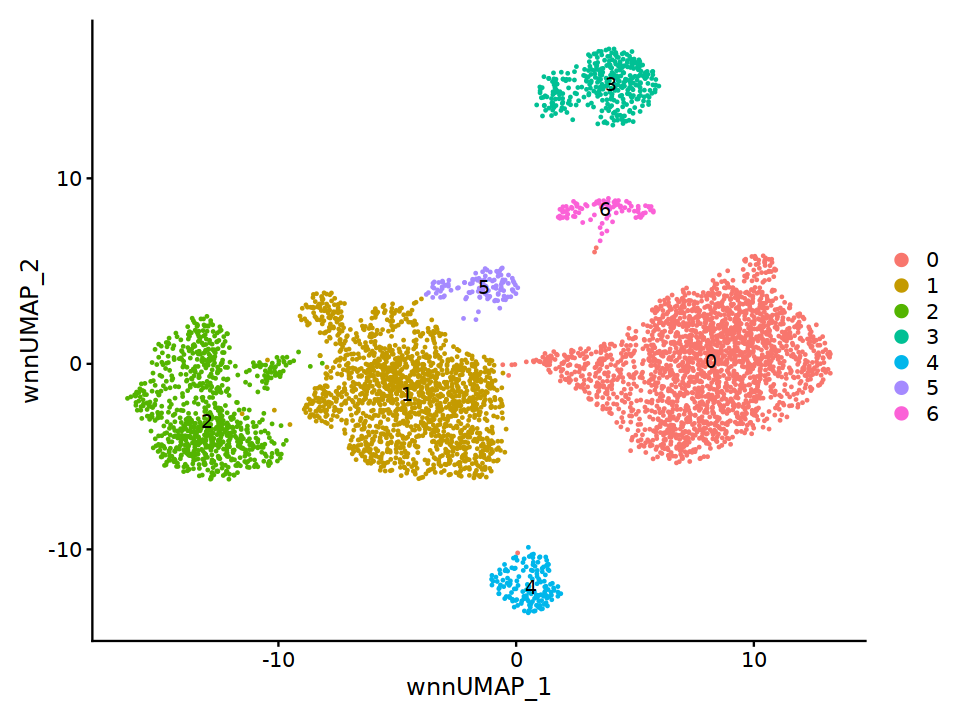

In [53]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

In [54]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, 
                              logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6



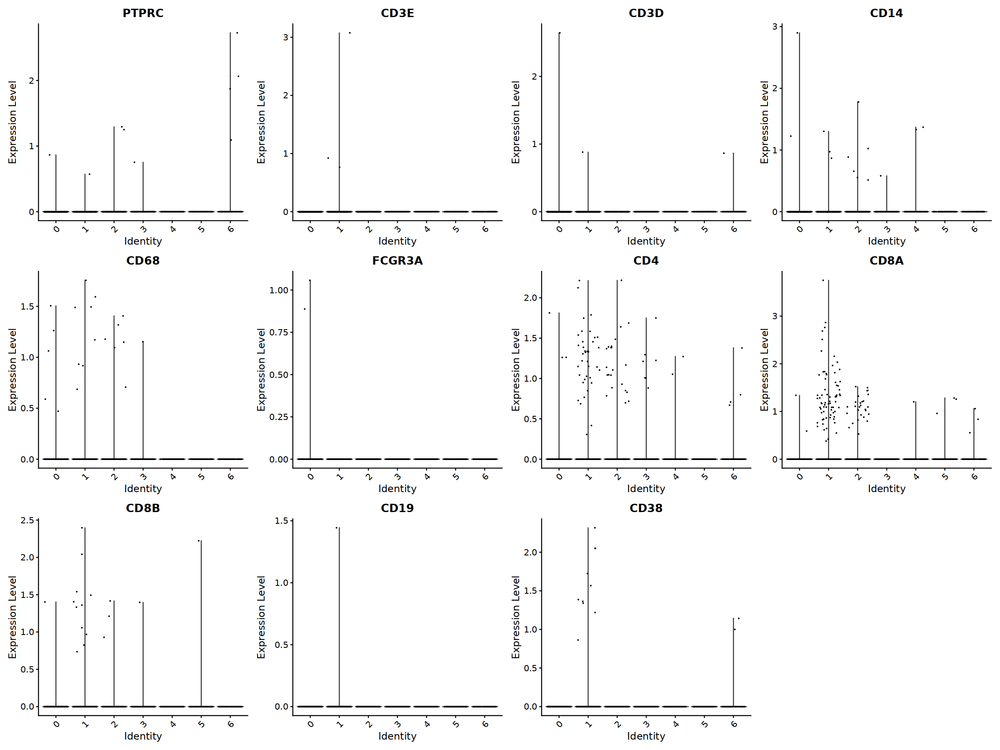

In [55]:
options(repr.plot.width = 20, repr.plot.height = 15)
VlnPlot(seurat_obj, feature=vars2plot, ncol = 4)

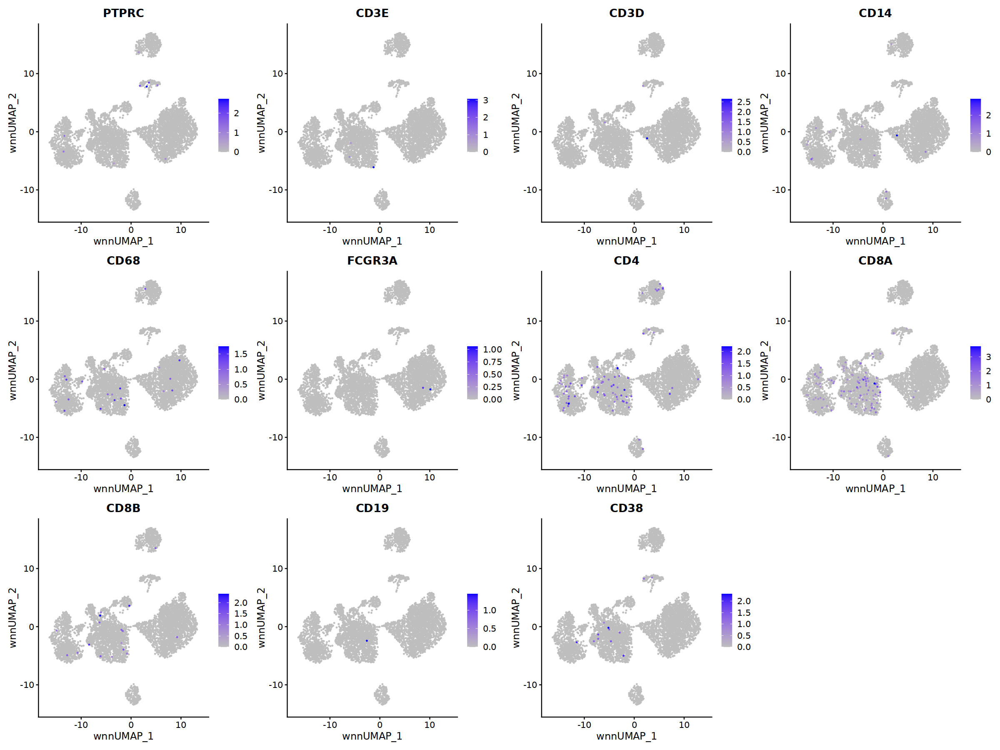

In [56]:
vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

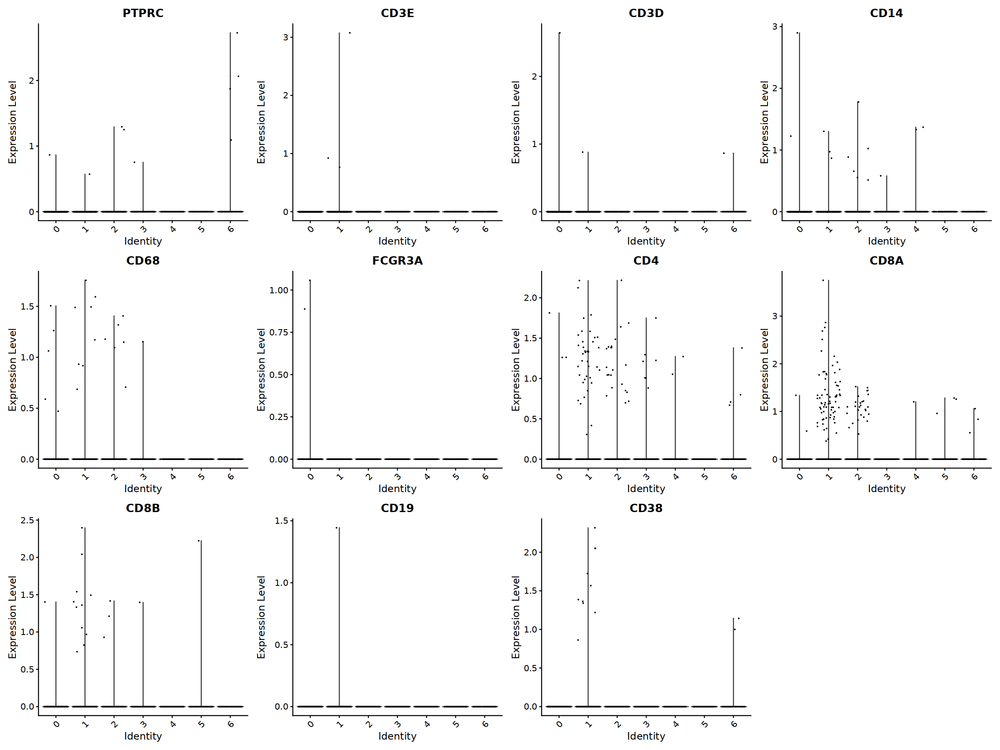

In [57]:
options(repr.plot.width = 20, repr.plot.height = 15)
VlnPlot(seurat_obj, feature=vars2plot, ncol = 4)

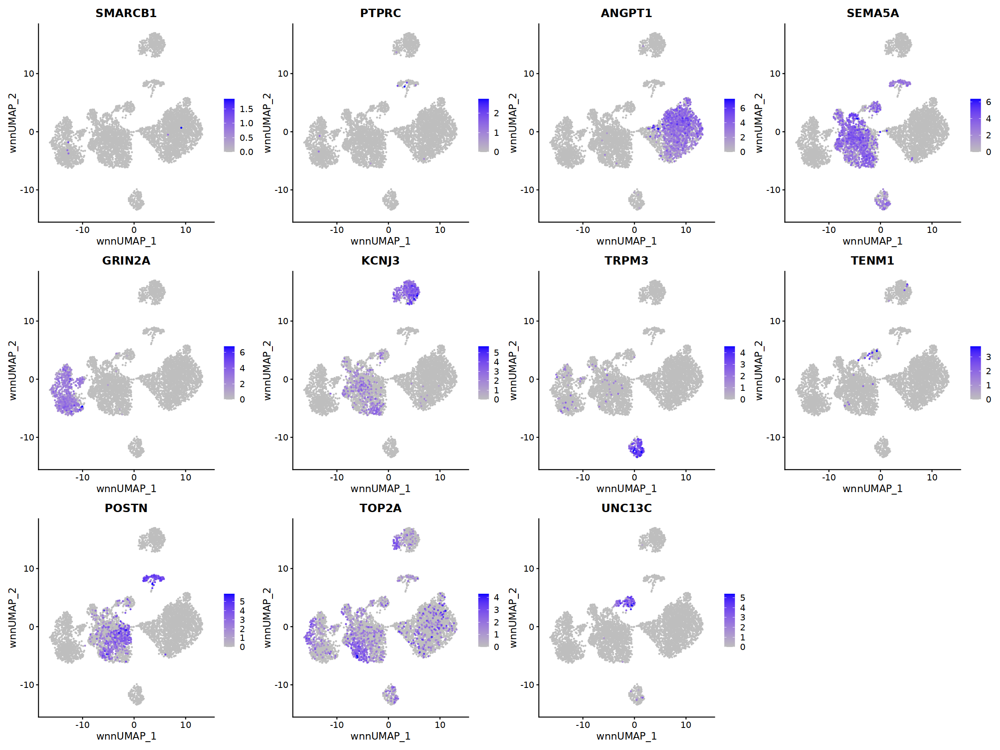

In [58]:
options(repr.plot.width = 20, repr.plot.height = 15)

vars2plot <- exp_genes_plot(c("SMARCB1","PTPRC", "ANGPT1",
                              "SEMA5A", "GRIN2A", "KCNJ3",
                              "TRPM3", "TENM1", "POSTN", "TOP2A",
                              "UNC13C"), seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

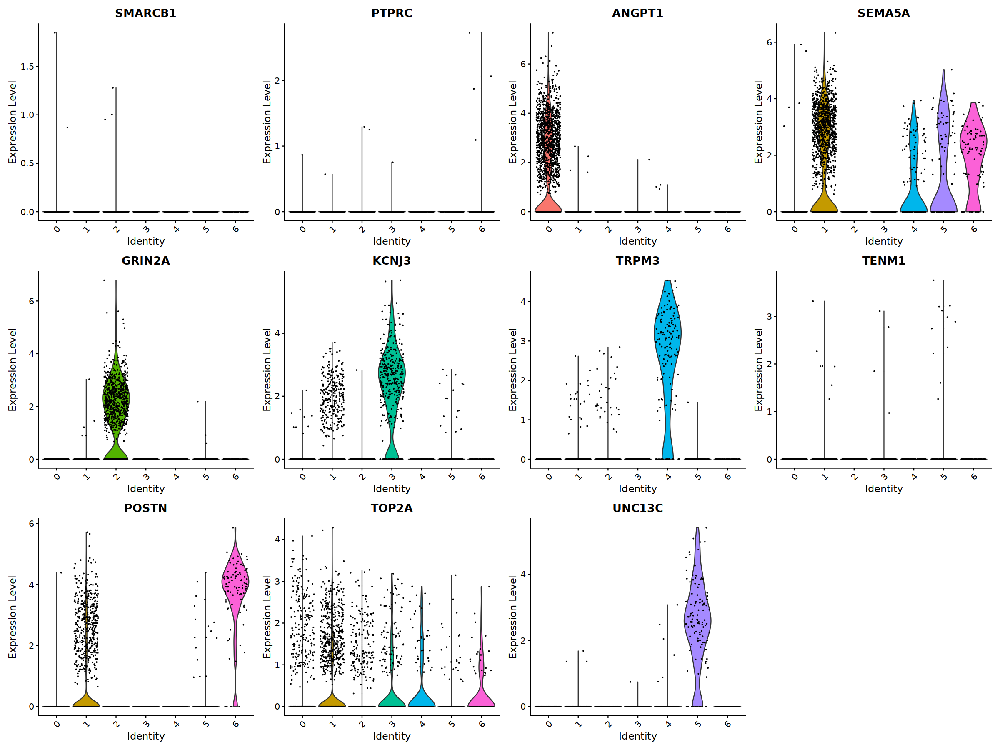

In [59]:
VlnPlot(seurat_obj, feature=vars2plot)

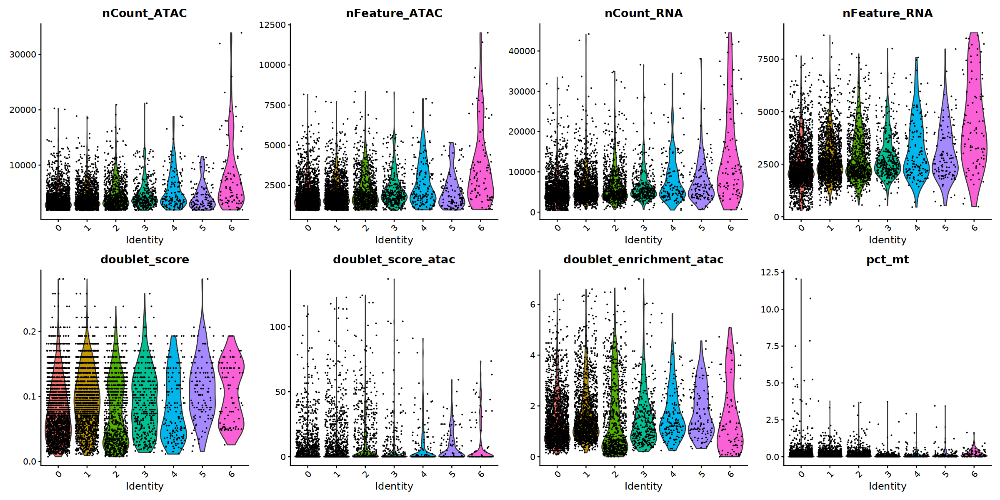

In [60]:
options(repr.plot.width = 20, repr.plot.height = 10)
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4)

In [61]:
rna.markers %>% 
  dplyr::filter(cluster == "5") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
UNC13C,0.000000e+00,4.603910,0.870,0.002,0.000000e+00,5,UNC13C
L3MBTL4,0.000000e+00,4.055715,0.426,0.002,0.000000e+00,5,L3MBTL4
C1orf21,5.457493e-166,3.071194,0.670,0.052,1.642378e-161,5,C1orf21
SYT1,2.390385e-34,2.835499,0.243,0.031,7.193625e-30,5,SYT1
ARHGAP28,1.032544e-283,2.252900,0.357,0.003,3.107338e-279,5,ARHGAP28
ANKFN12,9.911606e-31,2.029400,0.557,0.180,2.982799e-26,5,ANKFN1
FGD41,7.510240e-30,1.589230,0.365,0.078,2.260132e-25,5,FGD4
GPR1581,2.231780e-28,1.567432,0.617,0.210,6.716319e-24,5,GPR158
AC092691.12,8.632481e-45,1.482737,0.991,0.806,2.597859e-40,5,AC092691.1


## Rename

In [62]:
rename_clusters <- c("0"="Tumor ANGPT1", "1"="Tumor SEMA5A",
                     "2"="Tumor GRIN2A", "3"="Tumor KCNJ3",
                     "4"="Tumor TRPM3",  "5"="Tumor UNC13C", 
                     "6"="Fibroblast")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [63]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep]

In [64]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [65]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [66]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [67]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Other stromal



In [68]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

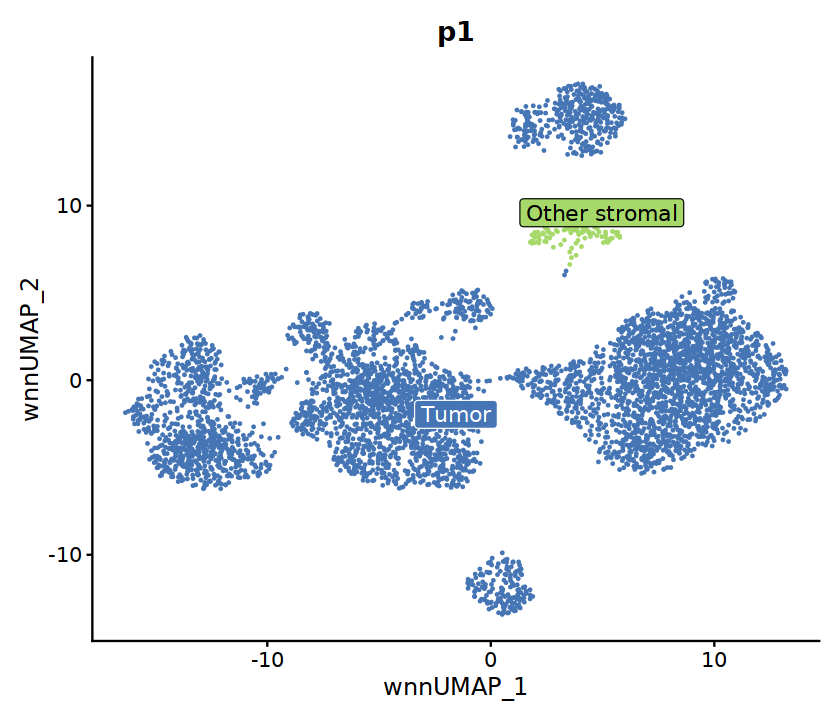

In [69]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [70]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [71]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [72]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

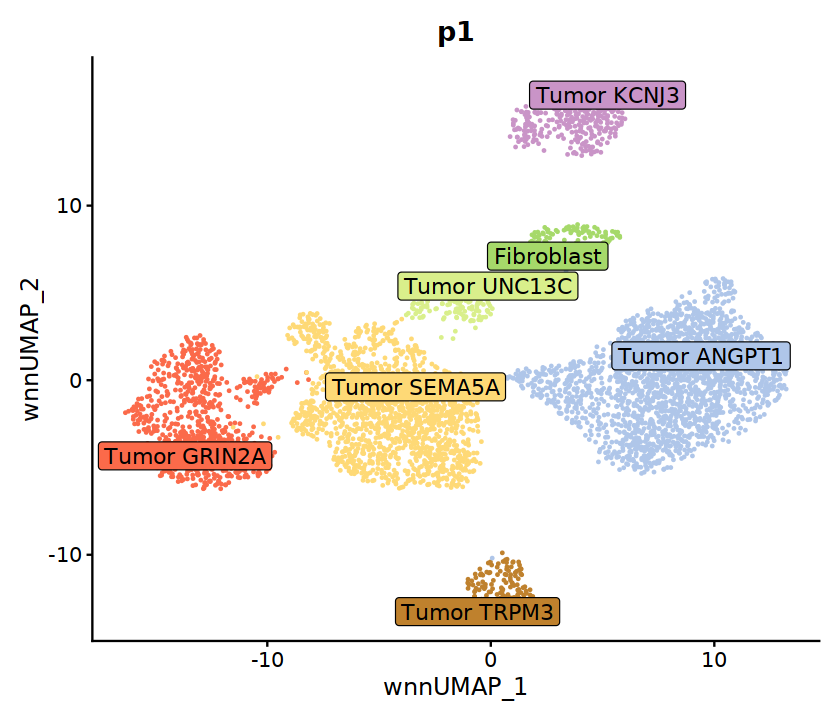

In [73]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [74]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

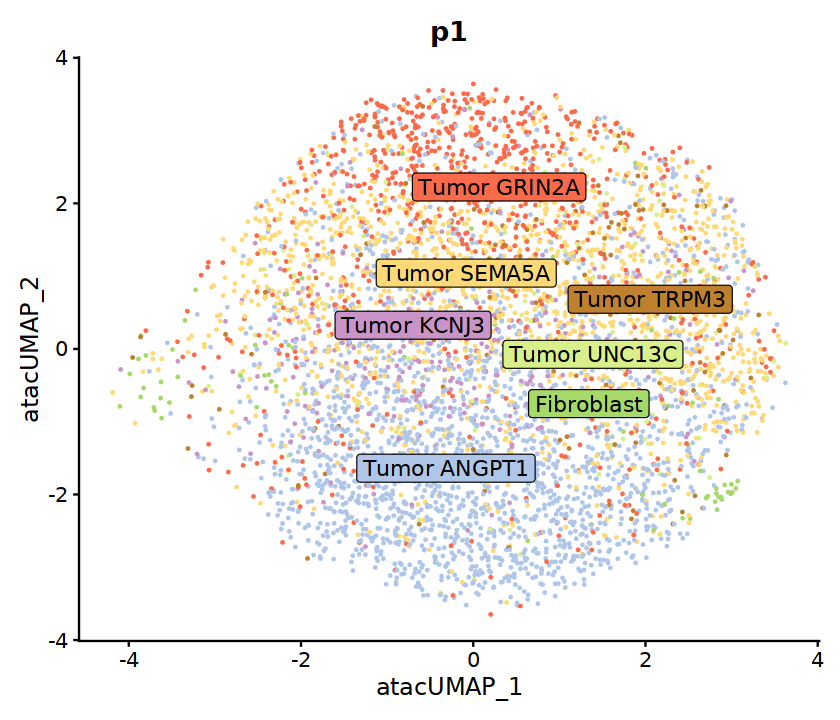

In [75]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [76]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

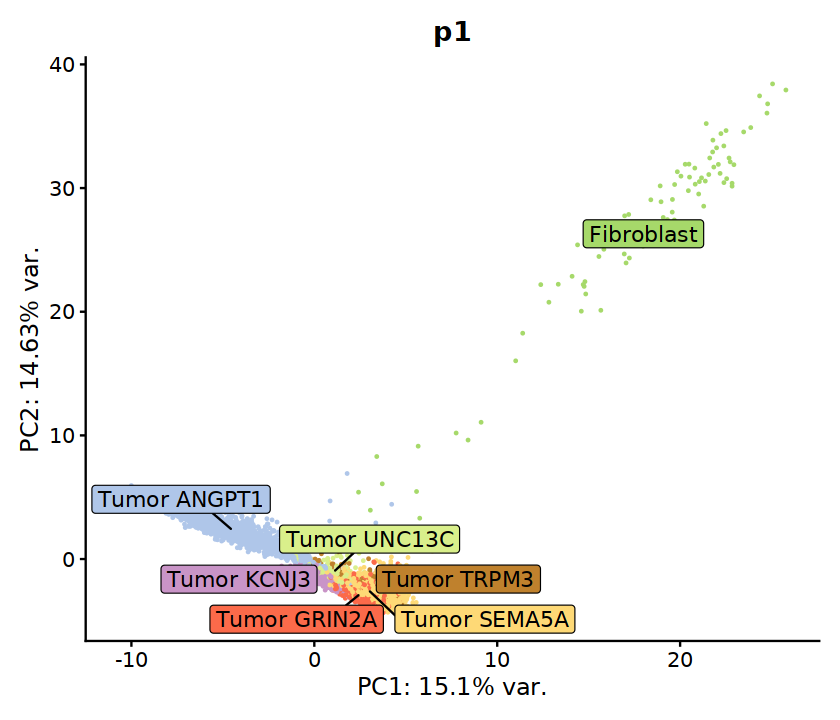

In [77]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

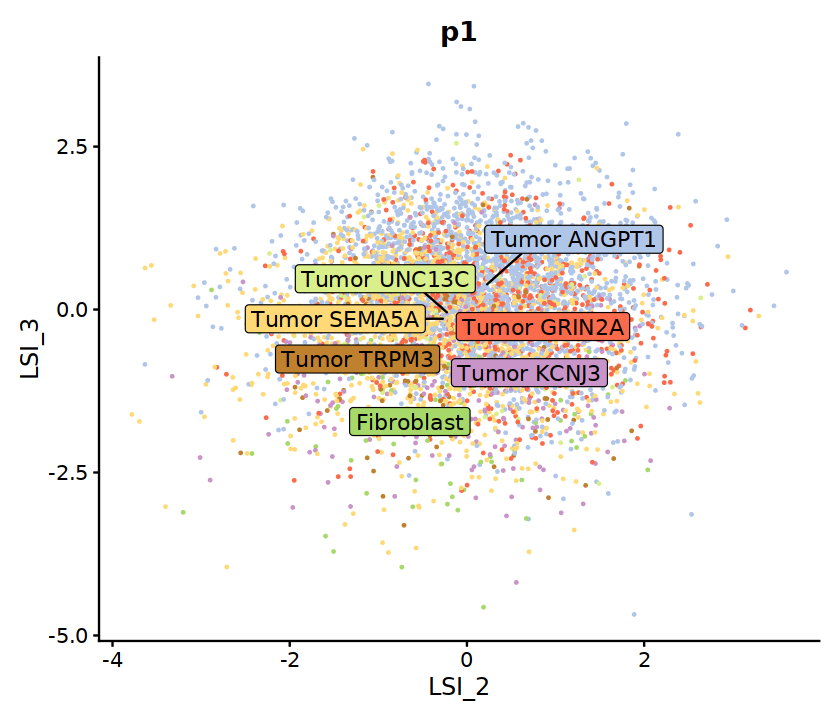

In [78]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

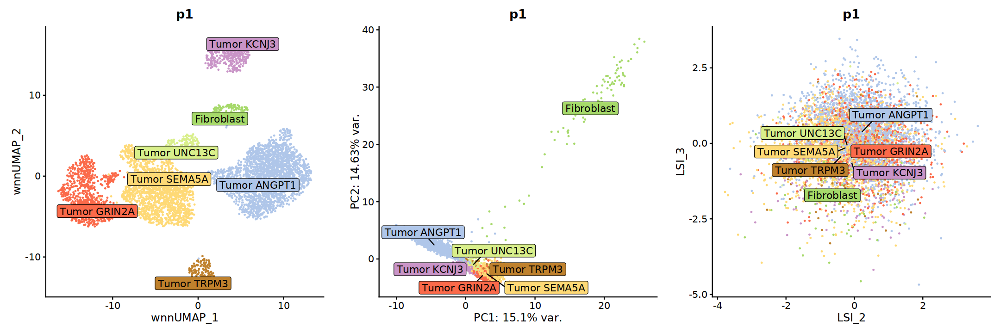

In [79]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [80]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [81]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("ROBO1", "ROBO2"), markers) ## common markers to all clusters

In [82]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

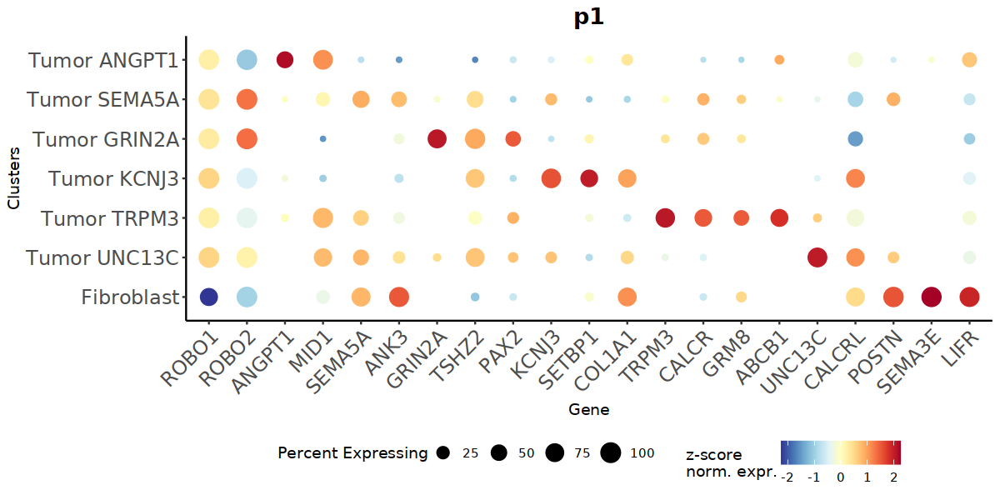

In [83]:
options(repr.plot.width = 10, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, unique(markers), TRUE,patient)
dp1

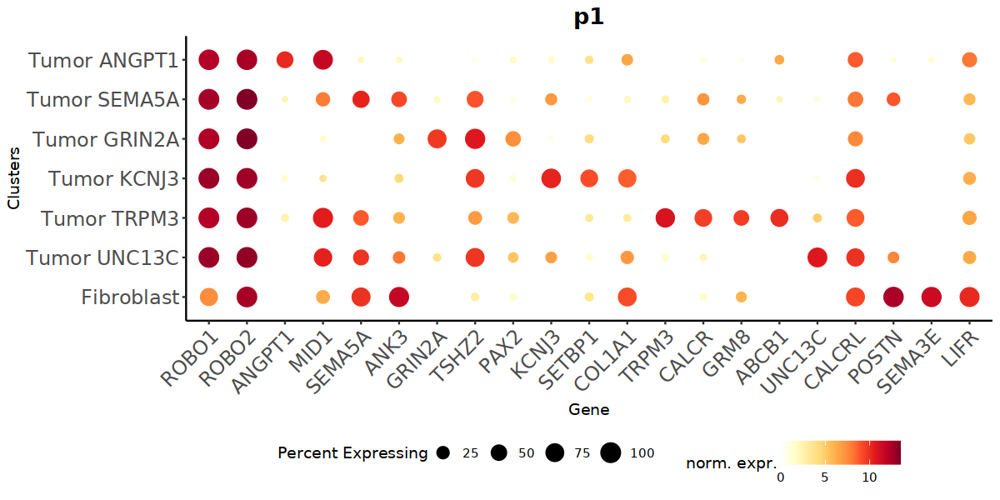

In [84]:
options(repr.plot.width = 10, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, unique(markers), FALSE,patient)
dp2

In [85]:
ggsave(plot = dp1, width = 10, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save 

In [86]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [87]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [88]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [89]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] Matrix_1.6-1.1              scater_1.22.0              
 [3] scran_1.22.1                scuttle_1.4.0              
 [5] SingleCellExperiment_1.16.0 SummarizedExperiment_1.24.0
 [7] Biobase_2.54.0              GenomicRanges_1.46.1       
 [9] GenomeInfoDb_1.30.